# AR(1) Model with Student-t(7) innovations

This notebook simulates an AR(1) time series with standardized Student-t(7) innovations, estimates Gaussian and SNP models, and compares their standardized residual QQ plots.

## 1. Import Required Libraries

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import t

import sys
sys.path.append('../')  # Add the parent directory to the Python path

from snpdenspy.snp.snp_distribution import SNPDistribution
from snpdenspy.util.diagnose.diagnose_fit import diagnose_fit

## 2. Simulate the data

Change phi and sigma if you wish.

In [17]:
# Parameters
phi = 0.7
sigma = 0.2
nsamples = 10000

# Generate standardized Student-t(7) innovations
np.random.seed(42)
noise = t.rvs(df=7, size=nsamples)
noise = (noise - noise.mean()) / noise.std(ddof=1)

# Simulate the AR(1) series with disturbance sigma * noise
x = np.zeros(shape=noise.shape)
x[0] = noise[0]
for i in range(1, len(x)):
    x[i] = phi * x[i - 1] + sigma * noise[i]

## 3. Define AR(1) Model Functions

In [18]:
def ar1_loc_scale(theta, x):
    phi, log_sigma = theta
    y = np.asarray(x)
    loc = phi * np.concatenate([[0.0], y[:-1]])  # simple AR(1) on lagged y
    scale = np.exp(log_sigma)
    return loc, scale


def ar1_gaussian_mle(x):
    """
    MLE for AR(1) with Gaussian noise and zero intercept.
    """
    y = np.asarray(x, dtype=float)
    x_lag = y[:-1]
    x_curr = y[1:]
    denom = float(np.dot(x_lag, x_lag))
    if denom == 0.0:
        raise ValueError("Cannot estimate AR(1) when lagged values are all zero.")
    phi_hat = float(np.dot(x_curr, x_lag) / denom)
    resid = x_curr - phi_hat * x_lag
    sigma_hat = float(np.sqrt(np.mean(resid ** 2)))
    return phi_hat, sigma_hat

## 4. Fit AR(1) + Normal noise

In [19]:
phi_norm, sigma_norm = ar1_gaussian_mle(x)
print(f"Normal-noise AR(1) MLE: phi={phi_norm:.4f}, sigma={sigma_norm:.4f}")

Normal-noise AR(1) MLE: phi=0.6947, sigma=0.2000


## 5. Fit AR(1) + SNP noise

In [20]:
K = 6
dist = SNPDistribution(K=K)
theta0 = np.array([0.1, np.log(np.std(x, ddof=1))])

res = dist.fit_mle(
    x=x,
    fit_loc=False, fit_scale=False,          # loc/scale driven by model
    loc_scale_fn=ar1_loc_scale,
    constrain_std_moments=True,
    loc_scale_params0=theta0,
    return_opt_result=True,
    method="L-BFGS-B",
)
c_hat = res["c"]
theta_hat = res["external_params"]
phi_snp, sigma_snp = theta_hat[0], np.exp(theta_hat[1])
loc_hat, scale_hat = res["loc"], res["scale"]
print(f"SNP-noise AR(1) MLE: phi={phi_snp:.4f}, sigma={sigma_snp:.4f}")

SNP-noise AR(1) MLE: phi=0.6943, sigma=0.2001


## 6. Visualize Model Fit

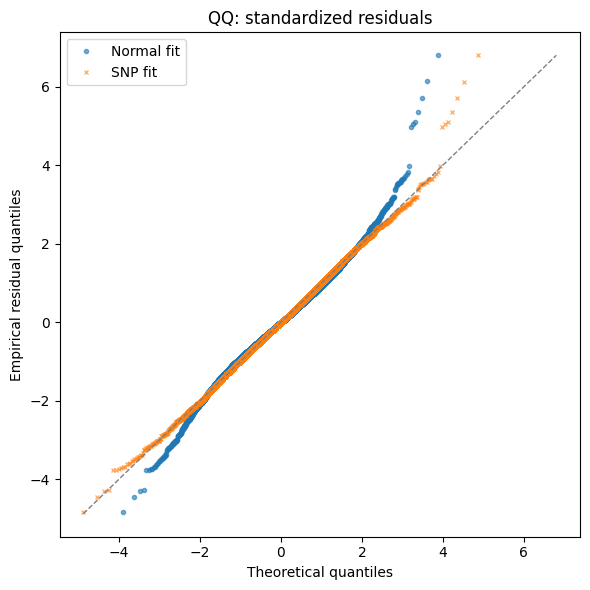

In [21]:
# QQ plots for residuals vs assumed Normal and fitted SNP noise
eps_norm = (x[1:] - phi_norm * x[:-1]) / sigma_norm
eps_snp = (x[1:] - phi_snp * x[:-1]) / sigma_snp

probs = (np.arange(1, len(eps_norm) + 1) - 0.5) / len(eps_norm)
emp_norm = np.sort(eps_norm)
emp_snp = np.sort(eps_snp)

q_norm = stats.norm.ppf(probs)
q_snp = SNPDistribution(K=K)(c=c_hat).ppf(probs)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(q_norm, emp_norm, "o", markersize=3, alpha=0.6, label="Normal fit")
ax.plot(q_snp, emp_snp, "x", markersize=3, alpha=0.6, label="SNP fit")
q_min = min(q_norm.min(), emp_norm.min(), q_snp.min(), emp_snp.min())
q_max = max(q_norm.max(), emp_norm.max(), q_snp.max(), emp_snp.max())
ax.plot([q_min, q_max], [q_min, q_max], "--", color="gray", linewidth=1)
ax.set_title("QQ: standardized residuals")
ax.set_xlabel("Theoretical quantiles")
ax.set_ylabel("Empirical residual quantiles")
ax.legend()

fig.tight_layout()
plt.show()

## 7. Evaluate Model Performance

The SNP fit is diagnose here. 


--- Fit summary ---
Fitted parameters:
c=[0.000 -0.010 -0.000 0.015 -0.000 0.000] loc=0.0000 scale=1.0000
Log-likelihood:   -14042.5488
Two-sample statistics vs fitted draws (empirical vs fitted):
  KS=  0.0094  CVM=  0.0000
Moment order  Empirical raw moment  Fitted raw moment
----------------------------------------------------------
 1             -0.0000        0.0000
 2              0.9999        1.0000
 3              0.0715       -0.0068
 4              4.4576        4.1140
 5              3.3361       -0.1022
    q    Empirical       Fitted
------------------------------------
  1%      -2.5358      -2.5667
  5%      -1.6099      -1.6045
 10%      -1.1959      -1.2061
 25%      -0.6015      -0.6152
 50%      -0.0057       0.0006
 75%       0.6055       0.6161
 90%       1.2105       1.2061
 95%       1.6337       1.6029
 99%       2.5111       2.5554


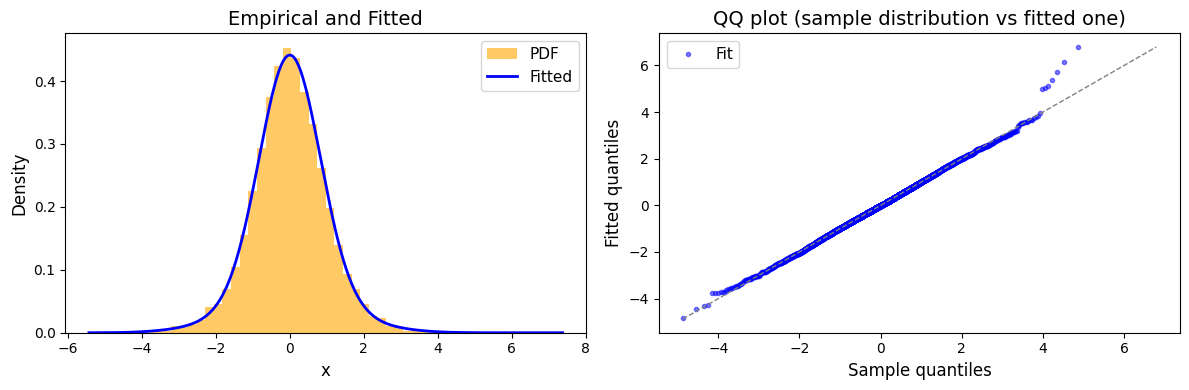

In [22]:
diagnose_fit(x=noise, fitted_dist=SNPDistribution(K=K)(c=c_hat))